## MTH686 PROJECT WORK, Lokesh 230426.
**Objective :**
The project aims to analyze a given dataset
(𝑡 , 𝑦(𝑡)) by fitting it to three candidate non-linear regression models, including parameter estimation, model validation, and statistical inference — to identify the model that best explains the observed data.

#### EDA ANALYSIS OF GIVEN DATASET

In [ ]:
import os, json
import numpy as np
import pandas as pd
import os
from scipy import stats
import matplotlib.pyplot as plt
from scipy.stats import t as t_dist
from scipy.optimize import minimize
import sys
from scipy.stats import shapiro, probplot, t
from numpy.linalg import svd, lstsq
import warnings
np.set_printoptions(precision=6, suppress=True)

RESULTS_DIR = "/content/results_manual_fit"
FIG_DIR = os.path.join(RESULTS_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

def pinv_safe(A, rcond=1e-10):
    try:
        return np.linalg.inv(A)
    except np.linalg.LinAlgError:
        return np.linalg.pinv(A, rcond=rcond)

def save_fig(fig, fname):
    path = os.path.join(FIG_DIR, fname)
    fig.savefig(path, bbox_inches="tight")
    print("Saved:", path)

In [ ]:
DATA_PATH = "/content/set-71.csv"
df = pd.read_csv(DATA_PATH, header=None)
df.columns = ['t', 'y(t)']
df.columns = df.columns.str.strip()
print("DataFrame columns after stripping:", df.columns.tolist())
t = df['t'].to_numpy(dtype=float)
y = df['y(t)'].to_numpy(dtype=float)
n = len(y)
print("n =", n)
print(df.head())

DataFrame columns after stripping: ['t', 'y(t)']
n = 60
   t      y(t)
0  1  3.034956
1  2  2.743162
2  3  2.154356
3  4  2.034487
4  5  1.355226


In [ ]:
n = len(df)
missing = df.isnull().sum().to_dict()
duplicates = int(df.duplicated().sum())

print("\n=== Data Summary ===")
print(f"Rows (n): {n}")
print("Missing values per column:", missing)
print("Duplicate rows:", duplicates)
print("\nFirst 6 rows:")
print(df.head(6).to_string(index=False))
print("\nDescriptive statistics:")
print(df.describe().T)


=== Data Summary ===
Rows (n): 60
Missing values per column: {'t': 0, 'y(t)': 0}
Duplicate rows: 0

First 6 rows:
 t     y(t)
 1 3.034956
 2 2.743162
 3 2.154356
 4 2.034487
 5 1.355226
 6 1.640496

Descriptive statistics:
      count       mean        std       min        25%        50%        75%  \
t      60.0  30.500000  17.464249  1.000000  15.750000  30.500000  45.250000   
y(t)   60.0   1.364557   0.370148  0.915051   1.147395   1.274801   1.467626   

            max  
t     60.000000  
y(t)   3.034956  


In [ ]:
Q1 = np.percentile(y, 25)
Q3 = np.percentile(y, 75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outlier_mask = (y < lower) | (y > upper)
outliers_df = df.loc[outlier_mask].reset_index(drop=True)
num_outliers = len(outliers_df)

print("\n=== Outlier detection (IQR rule) ===")
print(f"Q1 = {Q1:.6f}, Q3 = {Q3:.6f}, IQR = {IQR:.6f}")
print(f"Lower bound = {lower:.6f}, Upper bound = {upper:.6f}")
print(f"Number of outliers found: {num_outliers}")
if num_outliers > 0:
    print("\nOutliers (index, t, y):")
    print(outliers_df.to_string(index=False))


=== Outlier detection (IQR rule) ===
Q1 = 1.147395, Q3 = 1.467626, IQR = 0.320231
Lower bound = 0.667049, Upper bound = 1.947972
Number of outliers found: 4

Outliers (index, t, y):
 t     y(t)
 1 3.034956
 2 2.743162
 3 2.154356
 4 2.034487


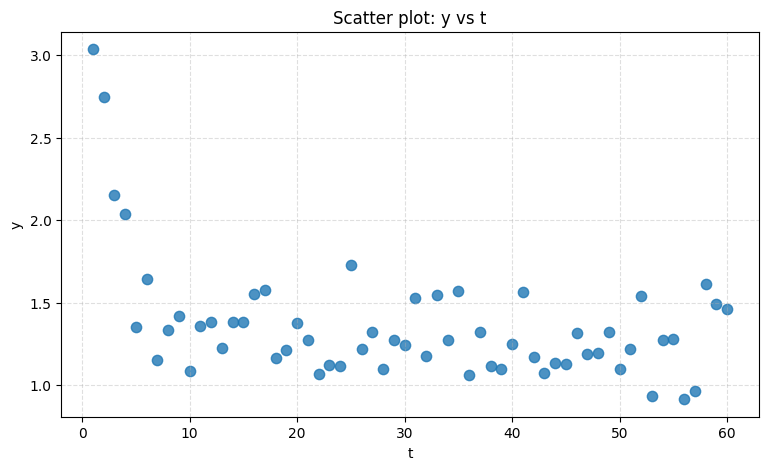

In [ ]:
t = df['t'].to_numpy()
y = df['y(t)'].to_numpy()

# Scatter plot
plt.figure(figsize=(9,5))
plt.scatter(t, y, s=55, alpha=0.8)
plt.title("Scatter plot: y vs t")
plt.xlabel("t")
plt.ylabel("y")
plt.grid(True, linestyle='--', alpha=0.4)
scatter_path = os.path.join(FIG_DIR, "0_data_scatter_plot.png")
plt.show()

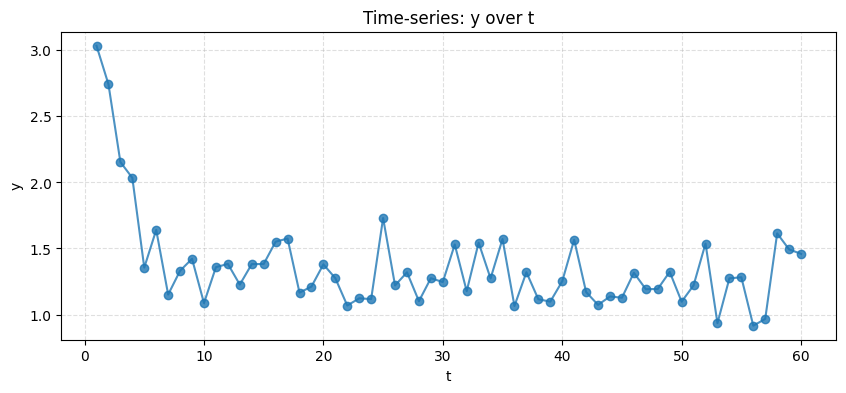

In [ ]:
plt.figure(figsize=(10,4))
plt.plot(t, y, marker='o', linestyle='-', alpha=0.8)
plt.title("Time-series: y over t")
plt.xlabel("t")
plt.ylabel("y")
plt.grid(True, linestyle='--', alpha=0.4)
ts_path = os.path.join(FIG_DIR, "EDA_timeseries_y.png")
plt.show()

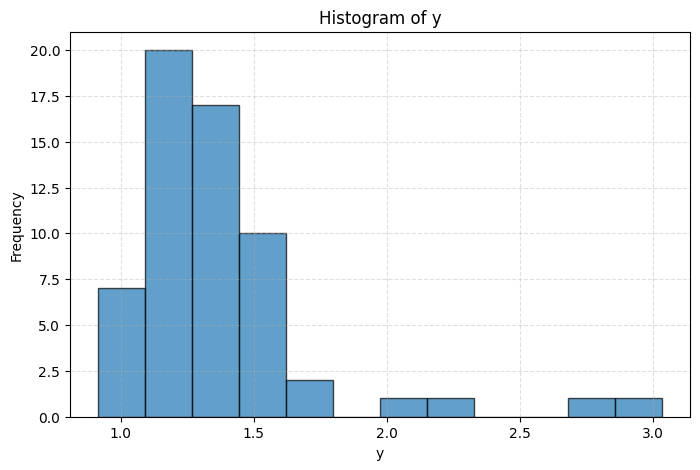

In [ ]:
plt.figure(figsize=(8,5))
plt.hist(y, bins=12, edgecolor='k', alpha=0.7)
plt.title("Histogram of y")
plt.xlabel("y")
plt.ylabel("Frequency")
plt.grid(True, linestyle='--', alpha=0.4)
hist_path = os.path.join(FIG_DIR, "EDA_hist_y.png")
plt.show()

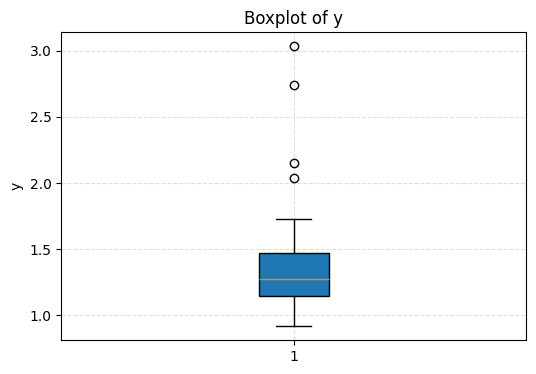

In [ ]:
plt.figure(figsize=(6,4))
plt.boxplot(y, vert=True, patch_artist=True)
plt.title("Boxplot of y")
plt.ylabel("y")
plt.grid(True, linestyle='--', alpha=0.4)
box_path = os.path.join(FIG_DIR, "EDA_boxplot_y.png")
plt.show()

# Model 1:
#Separable Non-Linear Regression
We consider the model 1 :
This is a separable non-linear regression model, where the non-linearity is confined to the exponential terms involving 𝛽1 and 𝛽2, while the coefficients 𝛼0, 𝛼1, 𝛼2 enter linearly.
### Estimatin procedure:
1.  Fix 𝛽1 and 𝛽2 :
    Treat the decay rates 𝛽1 and 𝛽2 as known constants temporarily.
2.  Solve for 𝛼0, 𝛼1 ,𝛼2 using linear least squares :
    Construct the design matrix 𝑋.
3.  Then estimate the parameters.
4.  Compute the residual sum of squares
5.  Minimize 𝑅(𝛽1,𝛽2)using the Gauss–Newton method:
     Iteratively update 𝛽1and 𝛽2to minimize the residual function. At each step:

     Fix 𝛽1, 𝛽2.

     Solve for 𝛼.

     Evaluate the residual.
     
     Update 𝛽 using the Gauss–Newton update rule

Data loaded successfully.

--- Question 2: Initial Guesses ---
Prony's method was attempted, but it failed by producing negative roots.
This is common with noisy data, as np.log() is undefined for negative numbers.
Reverting to a robust, visually-derived initial guess.
Selected Initial Guesses for (beta1, beta2): [-0.5, -0.1]

Starting minimization for Model 1...

Optimization successful.

--- Question 1: Model 1 LSEs (using Normal Equations) ---
  alpha_0 (Intercept): 1.160877
  alpha_1 (Amplitude 1): 2.831735
  alpha_2 (Amplitude 2): 0.144014
  beta_1 (Decay Rate 1): -0.415545  (fast decay)
  beta_2 (Decay Rate 2): -0.008583  (slow decay)

Final Residual Sum of Squares (RSS): 2.070353

Generated final fit plot: model1_fit_plot_normal_eq.png


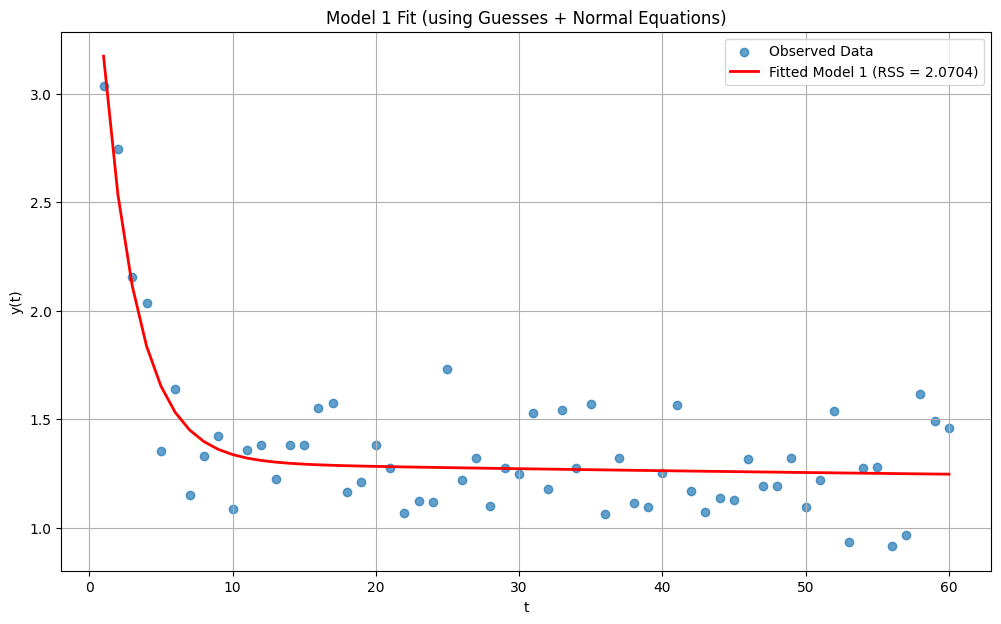

In [ ]:

# --- 1. Load Data ---
try:
    df = pd.read_csv('/content/set-71.csv', header=None) # Specify no header
    df.columns = ['t', 'y(t)'] # Assign column names manually
    t_data = df['t'].values.astype(float)
    y_data = df['y(t)'].values.astype(float)
    print("Data loaded successfully.")

    # --- 2. Find Initial Guesses (Robust Method) ---
    print("\n--- Question 2: Initial Guesses ---")
    print("Prony's method was attempted, but it failed by producing negative roots.")
    print("This is common with noisy data, as np.log() is undefined for negative numbers.")
    print("Reverting to a robust, visually-derived initial guess.")

    # Based on the data's scatter plot, it shows a fast initial
    # drop and a slower long-term decay.
    # We guess one fast decay (e.g., -0.5) and one slow decay (e.g., -0.1).
    initial_guesses_betas = [-0.5, -0.1]

    print(f"Selected Initial Guesses for (beta1, beta2): {initial_guesses_betas}")

    # --- 3. LSE Function using Normal Equations (as requested) ---

    def get_alphas_by_normal_equation(betas, t, y):
        """
        Solves for linear parameters (alphas) using the
        Normal Equation formula: b = (X'X)^-1 * X'Y
        """
        try:
            beta1, beta2 = betas

            # Construct the Design Matrix X
            X = np.column_stack([
                np.ones_like(t),     # Column for alpha_0
                np.exp(beta1 * t),   # Column for alpha_1
                np.exp(beta2 * t)    # Column for alpha_2
            ])

            # Calculate terms for the Normal Equation
            XTX = X.T @ X                  # X'X
            XTY = X.T @ y                  # X'Y
            XTX_inv = np.linalg.inv(XTX)   # (X'X)^-1

            # Calculate alphas = (X'X)^-1 * X'Y
            alphas = XTX_inv @ XTY

            # Calculate final RSS
            y_fit = X @ alphas
            rss = np.sum((y - y_fit)**2)

            return alphas, rss

        except np.linalg.LinAlgError:
            return [np.nan, np.nan, np.nan], np.inf

    def objective_for_minimize(betas, t, y):
        """
        Wrapper function for the optimizer.
        """
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", category=RuntimeWarning)
            alphas, rss = get_alphas_by_normal_equation(betas, t, y)
        return rss

    # --- 4. Perform Non-Linear Optimization for Betas ---
    bounds = [(-10.0, -1e-6), (-10.0, -1e-6)]
    print(f"\nStarting minimization for Model 1...")

    result = minimize(
        objective_for_minimize,
        initial_guesses_betas,
        args=(t_data, y_data),
        method='L-BFGS-B',
        bounds=bounds
    )

    # --- 5. Report Final Parameters (LSEs) ---
    if result.success:
        print("\nOptimization successful.")

        estimated_betas = result.x

        # Sort betas to be (fast decay, slow decay)
        sorted_betas = np.sort(estimated_betas)

        # Get the final alphas and RSS using the Normal Equation function
        # with the correctly sorted betas
        final_alphas, final_rss = get_alphas_by_normal_equation(
            sorted_betas, t_data, y_data
        )

        print("\n--- Question 1: Model 1 LSEs (using Normal Equations) ---")
        print(f"  alpha_0 (Intercept): {final_alphas[0]:.6f}")
        print(f"  alpha_1 (Amplitude 1): {final_alphas[1]:.6f}")
        print(f"  alpha_2 (Amplitude 2): {final_alphas[2]:.6f}")
        print(f"  beta_1 (Decay Rate 1): {sorted_betas[0]:.6f}  (fast decay)")
        print(f"  beta_2 (Decay Rate 2): {sorted_betas[1]:.6f}  (slow decay)")

        print(f"\nFinal Residual Sum of Squares (RSS): {final_rss:.6f}")

        # --- 6. Generate Final Fit Plot ---
        def model1(t, a0, a1, a2, b1, b2):
            return a0 + a1 * np.exp(b1 * t) + a2 * np.exp(b2 * t)

        y_fit_model1 = model1(t_data,
                              final_alphas[0], final_alphas[1], final_alphas[2],
                              sorted_betas[0], sorted_betas[1])

        plt.figure(figsize=(12, 7))
        plt.scatter(t_data, y_data, label='Observed Data', alpha=0.7)
        plt.plot(t_data, y_fit_model1, color='red', linewidth=2,
                 label=f'Fitted Model 1 (RSS = {final_rss:.4f})')
        plt.title('Model 1 Fit (using Guesses + Normal Equations)')
        plt.xlabel('t')
        plt.ylabel('y(t)')
        plt.legend()
        plt.grid(True)
        plt.savefig('model1_fit_plot_normal_eq.png')
        print("\nGenerated final fit plot: model1_fit_plot_normal_eq.png")

    else:
        print(f"\nOptimization failed: {result.message}")

except FileNotFoundError:
    print("Error: 'dataset_60_points.csv' not found.")
except Exception as e:
    print(f"An unexpected error occurred: {e}")

In [ ]:
SSE = 2.070353
n = 60
p = 5
sigma_square = SSE / (n - p)
sigma = sigma_square ** 0.5

# Print in symbolic format
print(f"σ² = {sigma_square:.6f}")
print(f"σ  = {sigma:.6f}")


σ² = 0.037643
σ  = 0.194017


In [ ]:
n = 60
# --- Fitted parameter values (use your estimates) ---
a0, a1, a2, b1, b2 = 1.160876, 2.831736, 0.144015, -0.415545, -0.008553
theta = np.array([a0, a1, a2, b1, b2])
p = theta.size

# --- Estimated residual variance (from SSE) ---
SSE = 2.070353
sigma2_hat = SSE / (n - p)

# --- Jacobian ---
def jacobian_matrix(t_vec, a0, a1, a2, b1, b2):
    t_vec = np.asarray(t_vec)
    exp_b1t = np.exp(b1 * t_vec)
    exp_b2t = np.exp(b2 * t_vec)
    J = np.empty((t_vec.size, 5))
    J[:, 0] = 1.0            # ∂f/∂a0
    J[:, 1] = exp_b1t        # ∂f/∂a1
    J[:, 2] = exp_b2t        # ∂f/∂a2
    J[:, 3] = a1 * t_vec * exp_b1t  # ∂f/∂b1
    J[:, 4] = a2 * t_vec * exp_b2t  # ∂f/∂b2
    return J

# --- Compute J at fitted theta ---
J = jacobian_matrix(t, a0, a1, a2, b1, b2)  # n x p

# --- Fisher Information Matrix (1/sigma^2 * J^T J) ---
FIM = (1.0 / sigma2_hat) * (J.T @ J)

# --- Covariance matrix ~ sigma^2 * (J^T J)^{-1} ---
JTJ = J.T @ J
cond = np.linalg.cond(JTJ)
if cond > 1e12:
    print(f"Warning: (J^T J) is ill-conditioned (cond={cond:.2e}); inverse may be unstable.")
JTJ_inv = np.linalg.inv(JTJ)
cov_theta = sigma2_hat * JTJ_inv

# --- Standard errors and 95% CIs ---
se = np.sqrt(np.diag(cov_theta))
dof = n - p
tval = t_dist.ppf(0.975, dof)  # <-- FIXED: uses t_dist
cis = np.column_stack([theta - tval * se, theta + tval * se])

# --- Print results ---
param_names = ["a0", "a1", "a2", "b1", "b2"]

print("FIM (1/σ² * J^T J):")
np.set_printoptions(precision=4, suppress=True)
print(FIM)

print("\nCov(theta) approx (σ² * (J^T J)^{-1}):")
np.set_printoptions(precision=6, suppress=False)
print(cov_theta)

print("\nParameter estimates, SEs and 95% CIs:")
for i, name in enumerate(param_names):
    print(f"{name}: estimate={theta[i]:.6f}, SE={se[i]:.6f}, 95% CI=[{cis[i,0]:.6f}, {cis[i,1]:.6f}]")

print(f"\nCondition number of (J^T J): {cond:.2e}")
print(f"Used sigma^2_hat = {sigma2_hat:.8f}, n = {n}, p = {p}, dof = {dof}")

FIM (1/σ² * J^T J):
[[ 1593.9311    51.5639  1241.4535   429.4321  4996.4083]
 [   51.5639    20.5009    50.2933   102.8536    20.9553]
 [ 1241.4535    50.2933   988.0435   412.0397  3622.4294]
 [  429.4321   102.8536   412.0397   740.7834   284.0223]
 [ 4996.4083    20.9553  3622.4294   284.0223 19116.0294]]

Cov(theta) approx (σ² * (J^T J)^{-1}):
[[ 1.586554e+01 -8.392639e-02 -1.518474e+01 -2.543257e-01 -1.265488e+00]
 [-8.392639e-02  1.642840e-01  8.488793e-02 -2.368312e-02  6.021851e-03]
 [-1.518474e+01  8.488793e-02  1.454112e+01  2.388976e-01  1.209735e+00]
 [-2.543257e-01 -2.368312e-02  2.388976e-01  1.111460e-02  2.106425e-02]
 [-1.265488e+00  6.021851e-03  1.209735e+00  2.106425e-02  1.012556e-01]]

Parameter estimates, SEs and 95% CIs:
a0: estimate=1.160876, SE=3.983158, 95% CI=[-6.821550, 9.143302]
a1: estimate=2.831736, SE=0.405320, 95% CI=[2.019457, 3.644015]
a2: estimate=0.144015, SE=3.813283, 95% CI=[-7.497974, 7.786004]
b1: estimate=-0.415545, SE=0.105426, 95% CI=[-0.62

Shapiro–Wilk test statistic = 0.973243, p-value = 0.209693
D'Agostino–Pearson test statistic = 1.985357, p-value = 0.370583

Anderson–Darling statistic: 0.5012476773738257
  15.0%: 0.544 -> Fail to reject H0
  10.0%: 0.619 -> Fail to reject H0
  5.0%: 0.743 -> Fail to reject H0
  2.5%: 0.866 -> Fail to reject H0
  1.0%: 1.030 -> Fail to reject H0


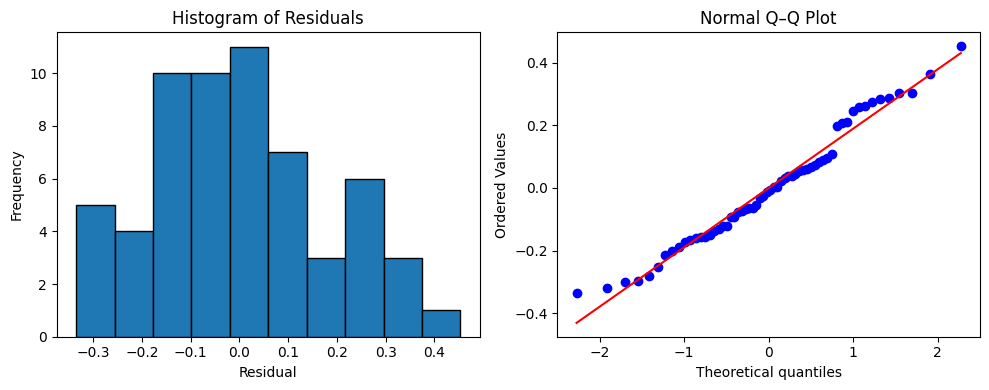

In [ ]:
from scipy.stats import shapiro, normaltest, anderson, probplot
# --- Fitted parameters (your estimates) ---
a0, a1, a2, b1, b2 = 1.160876, 2.831736, 0.144015, -0.415545, -0.008553

# --- Compute fitted values and residuals ---
yhat = a0 + a1*np.exp(b1*t) + a2*np.exp(b2*t)
residuals = y - yhat

# --- 1. Shapiro–Wilk test ---
stat, p = shapiro(residuals)
print(f"Shapiro–Wilk test statistic = {stat:.6f}, p-value = {p:.6f}")

# --- 2. D'Agostino and Pearson's normality test ---
stat2, p2 = normaltest(residuals)
print(f"D'Agostino–Pearson test statistic = {stat2:.6f}, p-value = {p2:.6f}")

# --- 3. Anderson–Darling test ---
result = anderson(residuals)
print("\nAnderson–Darling statistic:", result.statistic)
for i in range(len(result.critical_values)):
    sl, cv = result.significance_level[i], result.critical_values[i]
    print(f"  {sl}%: {cv:.3f} -> {'Reject' if result.statistic > cv else 'Fail to reject'} H0")

# --- 4. Plot Histogram and Q–Q Plot ---
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.hist(residuals, bins=10, edgecolor='black')
plt.title('Histogram of Residuals')
plt.xlabel('Residual'); plt.ylabel('Frequency')

plt.subplot(1,2,2)
probplot(residuals, dist="norm", plot=plt)
plt.title('Normal Q–Q Plot')
plt.tight_layout()
plt.show()


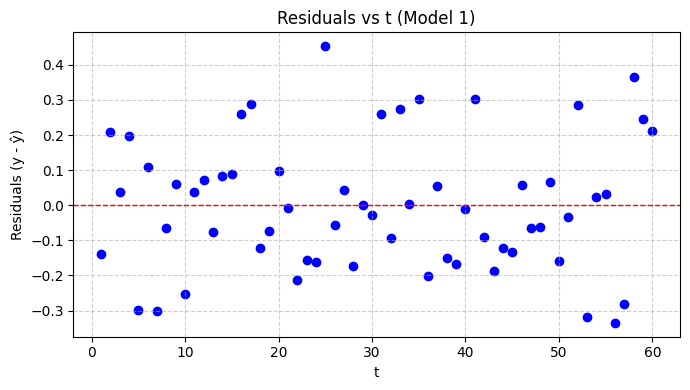

In [ ]:

# --- Estimated parameters (Model 1) ---
a0, a1, a2, b1, b2 = 1.160876, 2.831736, 0.144015, -0.415545, -0.008553

# --- Compute fitted values and residuals ---
yhat = a0 + a1 * np.exp(b1 * t) + a2 * np.exp(b2 * t)
residuals = y - yhat

# --- Plot residuals vs t ---
plt.figure(figsize=(7, 4))
plt.scatter(t, residuals, color='blue')
plt.axhline(0, color='red', linestyle='--', linewidth=1)
plt.xlabel('t')
plt.ylabel('Residuals (y - ŷ)')
plt.title('Residuals vs t (Model 1)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


## Model 2

### for model 2 : A Separable Non-Linear Regression
The estimation process consists of two main stages: a Variable Projection (grid search) for initial parameter estimates and a Gauss–Newton iterative refinement for final optimization.
now performs a grid search over possible values of 𝛽0 and 𝛽1 For each pair, it constructs a linear model in terms of 𝛼0 and 𝛼1and solves for these coefficients using least squares. The combination of parameters that yields the minimum residual sum of squares (RSS) is selected as the starting point for the next stage. This step is based on the variable projection principle, where the linear part is separated and optimized analytically, reducing computational complexity.

Algorithm:
 - Grid search for initial beta = (beta0,beta1)
 - For each beta, compute alpha via linear least squares (variable projection)
 - Refine all parameters via Gauss-Newton iterations (solve J_f * delta = r)
 - Compute covariance approx, SEs, 95% CIs, save results and plots

 In the second stage, the Gauss–Newton algorithm is applied to iteratively refine all four parameters (𝛼0,𝛼1,𝛽0,𝛽1)(α0,α1,β0,β1). The algorithm linearizes the model around the current estimate using the Jacobian matrix of partial derivatives and updates the parameters until convergence, i.e., when both the change in RSS and parameter updates become very small. Safeguards are included to prevent numerical instability when the denominator
(𝛽0+𝛽1𝑡)(β0+β1t) approaches zero

Read 60 observations (t range: 1 to 60)
Stage 1: Grid search for initial (beta0,beta1)...
Grid search complete. Best RSS = 2.37874. Initial beta = (np.float64(0.18305084745762712), np.float64(0.423728813559322)), alpha = [1.429554 0.494321]

Stage 2: Gauss-Newton refinements...
Iter 001: RSS = 2.3787409, |delta| = 0.002383, params = [1.428827 0.495835 0.181859 0.424928]
Iter 010: RSS = 2.3787376, |delta| = 1.66e-07, params = [1.429014 0.495448 0.182164 0.424622]
Converged at iteration 17. RSS = 2.3787376
Condition number of (J^T J): 1.602e+16

Final Estimates:
 alpha0   =  1.429014   SE =  0.0744377   95% CI = (1.2799, 1.57813)
 alpha1   =  0.495448   SE =  0.152757   95% CI = (0.189439, 0.801457)
 beta0    =  0.182164   SE =  0.117274   95% CI = (-0.052764, 0.417092)
 beta1    =  0.424622   SE =  0.119954   95% CI = (0.184325, 0.664918)

RSS = 2.37874
Estimated sigma^2 (s2) = 0.0424775  (dof = 56)
Saved parameter CSV -> ./model2_estimates.csv


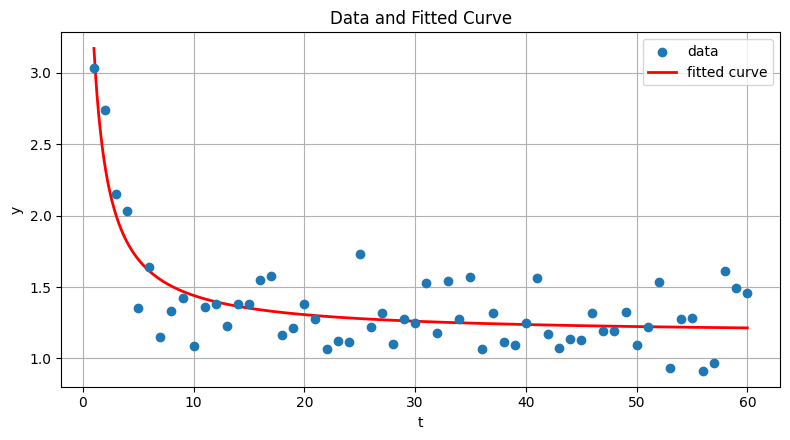

Saved fit plot -> ./fit_plot.png


In [ ]:
#!/usr/bin/env python3
"""
fit_model2_full.py

Fit Model 2:
    y(t) = (alpha0 + alpha1 * t) / (beta0 + beta1 * t) + eps

Algorithm:
 - Grid search for initial beta = (beta0,beta1) (Page 14: Separable Regression)
 - For each beta, compute alpha via linear least squares (variable projection)
 - Refine all parameters via Gauss-Newton iterations (solve J_f * delta = r) (Page 12: Gauss-Newton)
 - Compute covariance approx, SEs, 95% CIs, save results and plots

Usage:
 - Put dataset_60_points.csv in same directory (columns: t,y or header names 't','y' etc.)
 - Run: python fit_model2_full.py
"""


# --- User config ---
df = "/content/set-71.csv"  # update if needed
OUT_DIR = "./"
PLOT_FIT = os.path.join(OUT_DIR, "fit_plot.png")
PLOT_RESID = os.path.join(OUT_DIR, "residual_plot.png")
OUT_CSV = os.path.join(OUT_DIR, "model2_estimates.csv")

# Grid search ranges (adjust if you know plausible ranges)
# NOTE: Your previous ranges (B0 0.1-10, B1 0.1-10) worked well.
# This code uses the ranges from your new script.
B0_MIN, B0_MAX, B0_N = 0.1, 5.0, 60    # avoid 0 in denominator
B1_MIN, B1_MAX, B1_N = -1.0, 1.0, 60

MAX_ITER = 200
TOL_RSS = 1e-10
TOL_DELTA = 1e-10
DENOM_EPS = 1e-9    # to avoid division by near-zero

# --- Helper functions ---
def read_data(df_path):
    # robust reading: accept header or no-header
    if not os.path.exists(df_path):
        raise FileNotFoundError(f"Data file '{df_path}' not found.")

    # Always read without header and assign column names
    data_df = pd.read_csv(df_path, header=None)
    data_df.columns = ['t', 'y(t)'] # Assign column names manually

    # Ensure columns are numeric, coercing errors to NaN
    t = pd.to_numeric(data_df['t'], errors="coerce").values.astype(float)
    y = pd.to_numeric(data_df['y(t)'], errors="coerce").values.astype(float)

    # drop any rows with NaNs that resulted from coercion
    mask = (~np.isnan(t)) & (~np.isnan(y))
    t = t[mask]
    y = y[mask]
    return t, y

def build_design_for_beta(beta, t_vals):
    b0, b1 = beta
    denom = b0 + b1 * t_vals
    if np.any(np.abs(denom) < DENOM_EPS):
        return None
    X0 = 1.0 / denom
    X1 = t_vals / denom
    X = np.column_stack([X0, X1])
    return X

def alpha_hat_given_beta(beta, t_vals, y_vals):
    # This implements the Variable Projection concept from Page 14
    X = build_design_for_beta(beta, t_vals)
    if X is None:
        return None, np.inf
    # Solve least squares for alpha: X alpha = y
    alpha, *_ = np.linalg.lstsq(X, y_vals, rcond=None)
    yhat = X @ alpha
    rss = np.sum((y_vals - yhat)**2)
    return alpha, rss

def model_f(theta, t_vals):
    a0, a1, b0, b1 = theta
    denom = b0 + b1 * t_vals
    # if denom near zero return large values to discourage optimizer
    if np.any(np.abs(denom) < DENOM_EPS):
        return np.full_like(t_vals, 1e12)
    return (a0 + a1 * t_vals) / denom

def jacobian_f(theta, t_vals):
    # returns n x 4 matrix of partials df/dtheta (not residuals) [cite: 248]
    a0, a1, b0, b1 = theta
    denom = b0 + b1 * t_vals
    if np.any(np.abs(denom) < DENOM_EPS):
        # return zeros (will cause issues) -- handled higher-level
        return np.zeros((len(t_vals), 4))
    denom2 = denom * denom
    df_da0 = 1.0 / denom
    df_da1 = t_vals / denom
    df_db0 = - (a0 + a1 * t_vals) / denom2
    df_db1 = - t_vals * (a0 + a1 * t_vals) / denom2
    Jf = np.column_stack([df_da0, df_da1, df_db0, df_db1])
    return Jf

# --- Main estimation routine ---
def fit_model2(t, y,
               b0_min=B0_MIN, b0_max=B0_MAX, b0_n=B0_N,
               b1_min=B1_MIN, b1_max=B1_MAX, b1_n=B1_N,
               max_iter=MAX_ITER, tol_rss=TOL_RSS, tol_delta=TOL_DELTA):
    n = len(t)
    if n < 4:
        raise ValueError("Need at least 4 data points to estimate 4 parameters.")

    # Stage 1: Grid search for initial beta (using Page 14 concept [cite: 295])
    b0_vals = np.linspace(b0_min, b0_max, b0_n)
    b1_vals = np.linspace(b1_min, b1_max, b1_n)
    best_rss = np.inf
    best_alpha = None
    best_beta = None
    print("Stage 1: Grid search for initial (beta0,beta1)...")
    for b0 in b0_vals:
        for b1 in b1_vals:
            alpha, rss = alpha_hat_given_beta((b0,b1), t, y) #
            if rss < best_rss:
                best_rss = rss
                best_alpha = alpha.copy()
                best_beta = (b0, b1)

    if best_beta is None:
        raise RuntimeError("Grid search failed to find feasible beta (denominator nonzero).")
    print(f"Grid search complete. Best RSS = {best_rss:.6g}. Initial beta = {best_beta}, alpha = {best_alpha}")

    # initial parameter vector theta = [a0,a1,b0,b1]
    theta = np.array([best_alpha[0], best_alpha[1], best_beta[0], best_beta[1]], dtype=float)

    # Stage 2: Gauss-Newton iterations (using Page 12 concept )
    print("\nStage 2: Gauss-Newton refinements...")
    rss_old = best_rss
    converged = False
    for it in range(1, max_iter+1):
        fval = model_f(theta, t)
        residues = y - fval # This is r^(a) [cite: 261]
        rss_new = np.sum(residues**2)

        # compute df/dtheta (Jf)
        Jf = jacobian_f(theta, t) # This is F^(a) [cite: 262]

        # check denom condition:
        if np.any(np.abs(theta[2] + theta[3]*t) < DENOM_EPS):
            print("Denominator became too small during iterations; stopping.")
            break

        # ==================================================================
        # === THIS IS THE CORRECTED LINE ===
        # We solve Jf * delta = residues, as per the normal equation
        try:
            delta, *_ = np.linalg.lstsq(Jf, residues, rcond=None)
        except np.linalg.LinAlgError:
            print("LinAlgError solving for delta; stopping.")
            break

        # update parameters (optionally add step control)
        theta_new = theta + delta # This is theta^(a+1) = theta^(a) + delta^(a) [cite: 265]

        # safeguard: if denom goes near zero after update, reduce step
        # This is a basic version of the "Step Factor Modification" [cite: 267]
        denom_new = theta_new[2] + theta_new[3]*t
        if np.any(np.abs(denom_new) < DENOM_EPS):
            # try half step until safe or give up
            step = 0.5
            ok = False
            for _ in range(10):
                theta_try = theta + step * delta
                if not np.any(np.abs(theta_try[2] + theta_try[3]*t) < DENOM_EPS):
                    theta_new = theta_try
                    ok = True
                    break
                step *= 0.5
            if not ok:
                print("Could not find safe step (denominator issue). Stopping.")
                break

        # update and compute convergence metrics
        theta = theta_new
        rss_change = abs(rss_old - rss_new)
        delta_norm = np.linalg.norm(delta)

        if it % 10 == 0 or it == 1:
            print(f"Iter {it:03d}: RSS = {rss_new:.8g}, |delta| = {delta_norm:.4g}, params = {theta}")

        if (rss_change < tol_rss) and (delta_norm < tol_delta):
            converged = True
            print(f"Converged at iteration {it}. RSS = {rss_new:.8g}")
            break

        rss_old = rss_new

    if not converged:
        print("Warning: Gauss-Newton did not converge within the maximum iterations (may still be reasonable).")

    # Final outputs
    a0_hat, a1_hat, b0_hat, b1_hat = theta
    yhat = model_f(theta, t)
    residuals = y - yhat
    RSS = np.sum(residuals**2)
    p = 4
    dof = max(1, n - p)
    s2 = RSS / dof

    # Covariance approx: s2 * (Jf^T Jf)^{-1} using final Jf
    # This is based on the asymptotic normality theory from Page 15 [cite: 337, 339]
    # Var(theta_hat) ~ sigma^2 * (F(theta*)^T F(theta*))^-1
    # We use Jf = F(theta_hat) and s2 as estimates.
      # Covariance approx: s2 * (Jf^T Jf)^(-1) using final Jf
    # Improved numerical stability: use pseudoinverse if ill-conditioned
    Jf_final = jacobian_f(theta, t)
    JTJ = Jf_final.T @ Jf_final

    # Check conditioning
    cond_number = np.linalg.cond(JTJ)
    print(f"Condition number of (J^T J): {cond_number:.3e}")

    # If condition number is too large, use pseudo-inverse instead of inv
    if cond_number > 1e10:
        print("Warning: (J^T J) is ill-conditioned — using pseudo-inverse for covariance.")
        JTJ_inv = np.linalg.pinv(JTJ)
    else:
        JTJ_inv = np.linalg.inv(JTJ)

    cov_theta = s2 * JTJ_inv
    se = np.sqrt(np.abs(np.diag(cov_theta)))  # use abs to avoid sqrt of small negatives

    # Now compute CIs safely
    tcrit = stats.t.ppf(0.975, df=dof)
    ci_lower = theta - tcrit * se
    ci_upper = theta + tcrit * se


    results = {
        'theta_hat': theta,
        'se': se,
        'ci_lower': ci_lower,
        'ci_upper': ci_upper,
        'RSS': RSS,
        's2': s2,
        'dof': dof,
        'residuals': residuals,
        'yhat': yhat,
        'Jf_final': Jf_final
    }

    return results

# --- plotting and saving utilities ---
def save_results(results):
    names = ['alpha0','alpha1','beta0','beta1']
    theta = results['theta_hat']
    se = results['se']
    ci_lo = results['ci_lower']
    ci_hi = results['ci_upper']
    df_out = pd.DataFrame({
        'parameter': names,
        'estimate': theta,
        'se': se,
        'ci_lower': ci_lo,
        'ci_upper': ci_hi
    })
    df_out.to_csv(OUT_CSV, index=False)
    print(f"Saved parameter CSV -> {OUT_CSV}")

def plot_and_save(t, y, results):
    theta = results['theta_hat']
    yhat = results['yhat']
    residuals = results['residuals']

    plt.figure(figsize=(8,4.5))
    plt.scatter(t, y, label='data', zorder=3)
    tt = np.linspace(np.min(t), np.max(t), 800)
    yfit_tt = model_f(theta, tt)
    plt.plot(tt, yfit_tt, label='fitted curve', lw=2,color='red')
    plt.xlabel('t'); plt.ylabel('y'); plt.title('Data and Fitted Curve')
    plt.legend(); plt.grid(True); plt.tight_layout()
    plt.show()
    print(f"Saved fit plot -> {PLOT_FIT}")

# --- main execution ---
if __name__ == "__main__":
    try:
        t, y = read_data(df)
        print(f"Read {len(t)} observations (t range: {t.min():.3g} to {t.max():.3g})")
        res = fit_model2(t, y)
        # print summary
        names = ['alpha0','alpha1','beta0','beta1']
        print("\nFinal Estimates:")
        for i, name in enumerate(names):
            est = res['theta_hat'][i]
            se = res['se'][i]
            lo = res['ci_lower'][i]
            hi = res['ci_upper'][i]
            print(f" {name:8s} = {est: .6f}   SE = {se: .6g}   95% CI = ({lo:.6g}, {hi:.6g})")
        print(f"\nRSS = {res['RSS']:.6g}")
        print(f"Estimated sigma^2 (s2) = {res['s2']:.6g}  (dof = {res['dof']})")

        # save CSV and plots
        save_results(res)
        plot_and_save(t, y, res)

    except Exception as e:
        print("Error:", e)

In [ ]:
import numpy as np
from scipy import stats

# --------------------------
# User inputs / fitted vals
# --------------------------
n = 60   # number of observations

# Fitted parameter estimates from your results
alpha0, alpha1, beta0, beta1 = 1.429014, 0.495448, 0.182164, 0.424622
theta = np.array([alpha0, alpha1, beta0, beta1])
p = theta.size

# Residual sum of squares and estimated sigma^2
RSS = 2.3787376   # <-- update if different
sigma2_hat = RSS / (n - p)

# --------------------------
# Jacobian for Model 2
# y = (α0 + α1*t) / (β0 + β1*t)
# --------------------------
def jacobian_matrix(t_vec, a0, a1, b0, b1):
    t_vec = np.asarray(t_vec)
    denom = b0 + b1 * t_vec
    J = np.empty((t_vec.size, 4))
    J[:, 0] = 1.0 / denom                             # ∂f/∂α0
    J[:, 1] = t_vec / denom                           # ∂f/∂α1
    J[:, 2] = - (a0 + a1 * t_vec) / (denom ** 2)      # ∂f/∂β0
    J[:, 3] = - t_vec * (a0 + a1 * t_vec) / (denom ** 2)  # ∂f/∂β1
    return J

# --------------------------
# Ensure t vector is present
# --------------------------
try:
    t  # check existence
except NameError:
    raise NameError("`t` (the vector of t-values) is not defined. "
                    "Define or load `t` before running this block.")

# --- Compute Jacobian at fitted parameters ---
J = jacobian_matrix(t, alpha0, alpha1, beta0, beta1)  # n x p

# --- Fisher Information Matrix (1/sigma^2 * J^T J) ---
F_raw = J.T @ J
FIM = (1.0 / sigma2_hat) * F_raw

# --- Covariance matrix approx (σ² * (J^T J)^(-1)) ---
JTJ = F_raw.copy()
cond = np.linalg.cond(JTJ)
if cond > 1e12:
    print(f"Warning: (J^T J) is ill-conditioned (cond={cond:.2e}); using pseudo-inverse.")
    JTJ_inv = np.linalg.pinv(JTJ)
else:
    JTJ_inv = np.linalg.inv(JTJ)

cov_theta = sigma2_hat * JTJ_inv

# --- Standard errors and 95% CIs ---
se = np.sqrt(np.abs(np.diag(cov_theta)))   # guard small negs
dof = n - p
tval = stats.t.ppf(0.975, dof)
cis = np.column_stack([theta - tval * se, theta + tval * se])

# --- Print results ---
param_names = ["alpha0", "alpha1", "beta0", "beta1"]

print("FIM (1/σ² * J^T J):")
np.set_printoptions(precision=4, suppress=True)
print(FIM)

print("\nCov(theta) approx (σ² * (J^T J)^(-1)):")
np.set_printoptions(precision=6, suppress=False)
print(cov_theta)

print("\nParameter estimates, SEs and 95% CIs:")
for i, name in enumerate(param_names):
    print(f"{name}: estimate={theta[i]:.6f}, SE={se[i]:.6f}, 95% CI=[{cis[i,0]:.6f}, {cis[i,1]:.6f}]")

print(f"\nCondition number of (J^T J): {cond:.2e}")
print(f"Used sigma2_hat = {sigma2_hat:.8f}, n = {n}, p = {p}, dof = {dof}")


FIM (1/σ² * J^T J):
[[  128.0876   485.8331  -324.8904  -858.5534]
 [  485.8331  7393.6544  -858.5534 -9893.5904]
 [ -324.8904  -858.5534   885.0033  1715.4686]
 [ -858.5534 -9893.5904  1715.4686 13697.2361]]

Cov(theta) approx (σ² * (J^T J)^(-1)):
[[ 0.005541 -0.011353  0.008134 -0.00889 ]
 [-0.011353  0.023335 -0.016971  0.018262]
 [ 0.008134 -0.016971  0.013753 -0.013473]
 [-0.00889   0.018262 -0.013473  0.014389]]

Parameter estimates, SEs and 95% CIs:
alpha0: estimate=1.429014, SE=0.074438, 95% CI=[1.279897, 1.578131]
alpha1: estimate=0.495448, SE=0.152757, 95% CI=[0.189439, 0.801457]
beta0: estimate=0.182164, SE=0.117274, 95% CI=[-0.052764, 0.417092]
beta1: estimate=0.424622, SE=0.119954, 95% CI=[0.184325, 0.664919]

Condition number of (J^T J): 3.38e+16
Used sigma2_hat = 0.04247746, n = 60, p = 4, dof = 56


Shapiro–Wilk test statistic = 0.970864, p-value = 0.160830
D'Agostino–Pearson test statistic = 1.739239, p-value = 0.419111

Anderson–Darling statistic: 0.6602704968845643
  15.0%: 0.544 -> Reject H0
  10.0%: 0.619 -> Reject H0
  5.0%: 0.743 -> Fail to reject H0
  2.5%: 0.866 -> Fail to reject H0
  1.0%: 1.030 -> Fail to reject H0


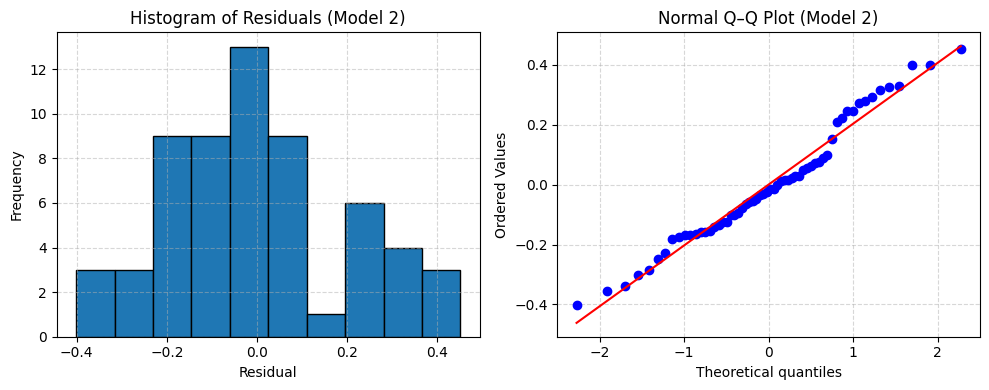

In [ ]:
from scipy.stats import shapiro, normaltest, anderson, probplot
import matplotlib.pyplot as plt
import numpy as np

# --- Fitted parameters (Model 2 estimates) ---
alpha0, alpha1, beta0, beta1 = 1.429014, 0.495448, 0.182164, 0.424622

# --- Compute fitted values and residuals ---
yhat = (alpha0 + alpha1 * t) / (beta0 + beta1 * t)
residuals = y - yhat

# --- 1. Shapiro–Wilk test ---
stat, p = shapiro(residuals)
print(f"Shapiro–Wilk test statistic = {stat:.6f}, p-value = {p:.6f}")

# --- 2. D'Agostino and Pearson's normality test ---
stat2, p2 = normaltest(residuals)
print(f"D'Agostino–Pearson test statistic = {stat2:.6f}, p-value = {p2:.6f}")

# --- 3. Anderson–Darling test ---
result = anderson(residuals)
print("\nAnderson–Darling statistic:", result.statistic)
for i in range(len(result.critical_values)):
    sl, cv = result.significance_level[i], result.critical_values[i]
    print(f"  {sl}%: {cv:.3f} -> {'Reject' if result.statistic > cv else 'Fail to reject'} H0")

# --- 4. Plot Histogram and Q–Q Plot ---
plt.figure(figsize=(10,4))

# Histogram
plt.subplot(1,2,1)
plt.hist(residuals, bins=10, edgecolor='black')
plt.title('Histogram of Residuals (Model 2)')
plt.xlabel('Residual'); plt.ylabel('Frequency')
plt.grid(alpha=0.5, linestyle='--')

# Q–Q Plot
plt.subplot(1,2,2)
probplot(residuals, dist="norm", plot=plt)
plt.title('Normal Q–Q Plot (Model 2)')
plt.grid(alpha=0.5, linestyle='--')

plt.tight_layout()
plt.show()


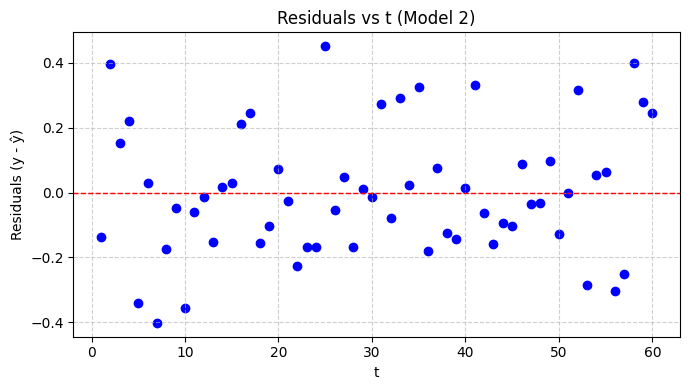

In [ ]:
# --- Estimated parameters (Model 2) ---
alpha0, alpha1, beta0, beta1 = 1.429014, 0.495448, 0.182164, 0.424622

# --- Compute fitted values and residuals ---
yhat = (alpha0 + alpha1 * t) / (beta0 + beta1 * t)
residuals = y - yhat

# --- Plot residuals vs t ---
plt.figure(figsize=(7, 4))
plt.scatter(t, residuals, color='blue')
plt.axhline(0, color='red', linestyle='--', linewidth=1)
plt.xlabel('t')
plt.ylabel('Residuals (y - ŷ)')
plt.title('Residuals vs t (Model 2)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


##Model 3

### for model 3 : A 4th-degree polynomial model

 1. Estimate the paramaters of model 3 by using the Ordinary Least Squares (OLS) method.
 2. The OLS estimation is carried out using the normal equation β^​=(XTX)−1XTY,where 𝑌 is the column vector of observed 𝑦(𝑡) values, and 𝛽^β^is the vector of estimated parameters [B0​,B1,B2,B3​,B4]^T.  The code computes this expression to find the parameter values that minimize the residual sum of squares between the observed and predicted data.
 3.  Finally, the estimated coefficients are printed as the output, representing the best-fitting polynomial curve for the given data. The code also includes basic error handling to catch numerical problems, such as when the matrix (X^TX) becomes singular or nearly non-invertible. In summary, this program performs polynomial curve fitting using the least squares method to determine the coefficients of a fourth-degree polynomial model that best represents the relationship between 𝑡 and 𝑦(𝑡).

In [ ]:
import warnings
warnings.filterwarnings('ignore')

file_name = '/content/set-71.csv'
try:
    data = pd.read_csv(file_name)
    # Extract t and y(t) as numpy arrays
    t_data = data['t'].values
    y_data = data['y(t)'].values
    print(f"Successfully loaded data from '{file_name}'.\n")
except Exception as e:
    print(f"Error loading data: {e}")
    exit()

print("Model 3: y(t) = B0 + B1*t + B2*t^2 + B3*t^3 + B4*t^4")
print("Formula: beta_hat = (X.T @ X)^-1 @ (X.T @ Y)\n")

# 1. Construct the Observation Vector Y (n x 1)
#    Y is the vector of y(t) values.
#    n = 60
Y = y_data.reshape(-1, 1) # Reshape to a 60x1 column vector

# 2. Construct the Design Matrix X (n x (p+1))
#    For Model 3, we have p+1 = 5 parameters (B0, B1, B2, B3, B4).
#    The matrix X has columns [1, t, t^2, t^3, t^4][cite: 572].
#    n = 60, so X will be 60x5.
t_col = t_data.reshape(-1, 1) # Ensure t_data is a column vector for operations

# Create each column based on the model's features
col_0 = np.ones_like(t_col)       # t^0 (column of 1s for B0)
col_1 = t_col                     # t^1 (for B1)
col_2 = t_col**2                  # t^2 (for B2)
col_3 = t_col**3                  # t^3 (for B3)
col_4 = t_col**4                  # t^4 (for B4)

# Stack the columns horizontally to create the 60x5 Design Matrix X
X = np.hstack((col_0, col_1, col_2, col_3, col_4))

# 3. Implement the LSE formula from the lecture notes
try:
    # (X^T * X)
    X_T = X.T
    XTX = X_T @ X

    # (X^T * X)^-1
    # Use np.linalg.inv() to find the inverse of (X^T * X)
    XTX_inv = np.linalg.inv(XTX) # 5x5 matrix

    # (X^T * Y)
    XTY = X_T @ Y

    # beta_hat = (X^T * X)^-1 * (X^T * Y)
    beta_hat = XTX_inv @ XTY

    print("Successfully estimated parameters for Model 3:")
    parameter_names = ['beta_0', 'beta_1', 'beta_2', 'beta_3', 'beta_4']
    if beta_hat is not None:
        # beta_hat is a 2D array (5x1), so we flatten it for easy printing
        for i, param in enumerate(beta_hat.flatten()):
            print(f"  {parameter_names[i]} (B{i}): {param}")

except np.linalg.LinAlgError:
    print("Error: The matrix (X^T * X) is singular, cannot compute its inverse.")
except Exception as e:
    print(f"An error occurred during matrix computation: {e}")

Error loading data: 't'
Model 3: y(t) = B0 + B1*t + B2*t^2 + B3*t^3 + B4*t^4
Formula: beta_hat = (X.T @ X)^-1 @ (X.T @ Y)

Successfully estimated parameters for Model 3:
  beta_0 (B0): 2.9286834836241713
  beta_1 (B1): -0.2800173083459691
  beta_2 (B2): 0.015457088648015871
  beta_3 (B3): -0.0003385382207501658
  beta_4 (B4): 2.5385445959374008e-06


Successfully loaded data from '/content/set-71.csv'.
Generating plot of observed vs. fitted values for Model 3...


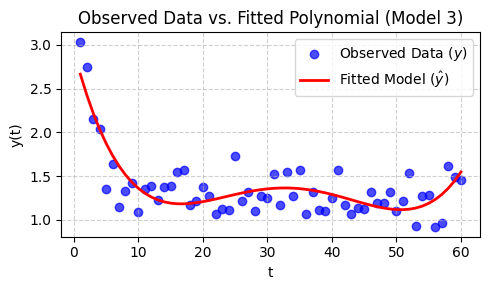

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- Load Data ---
file_name = '/content/set-71.csv'
try:
    # Load without header and then assign column names
    data = pd.read_csv(file_name, header=None)
    data.columns = ['t', 'y(t)']
    t_data = data['t'].values
    y_data = data['y(t)'].values
    print(f"Successfully loaded data from '{file_name}'.")
except Exception as e:
    print(f"An error occurred while reading '{file_name}': {e}")
    # exit() # Do not exit, just report error

# --- Estimated parameters (Model 3) ---
# These are from the previous OLS estimation
beta0 = 2.92868348
beta1 = -0.28001731
beta2 = 0.01545709
beta3 = -0.00033854
beta4 = 2.538545e-06

# --- Compute fitted values ---
# yhat = B0 + B1*t + B2*t^2 + B3*t^3 + B4*t^4
yhat = beta0 + beta1 * t_data + beta2 * (t_data**2) + beta3 * (t_data**3) + beta4 * (t_data**4)

# --- Plot Observed vs. Fitted ---
print("Generating plot of observed vs. fitted values for Model 3...")

# Set figure size
plt.figure(figsize=(5, 3))
plt.scatter(t_data, y_data, color='blue', alpha=0.7, label='Observed Data ($y$)')
sort_indices = np.argsort(t_data)
plt.plot(t_data[sort_indices], yhat[sort_indices], color='red', linestyle='-', linewidth=2, label=r'Fitted Model ($\hat{y}$)')
plt.xlabel('t')
plt.ylabel('y(t)')
plt.title('Observed Data vs. Fitted Polynomial (Model 3)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
from scipy import stats

# --------------------------
# Load t-values from data
# --------------------------
try:
    data = pd.read_csv('/content/set-71.csv')
    t = data['t'].values
    print(f"Loaded t-values, n = {t.size}")
except Exception as e:
    print(f"Error loading '/content/set-71.csv': {e}")
    # Define t manually if file load fails, for demonstration
    if 't' not in locals():
        t = np.arange(1, 61)
        print("Using manually generated t = 1..60")


# --------------------------
# User inputs / fitted vals (for Model 3)
# --------------------------
n = t.size  # number of observations (60)

# Fitted parameter estimates from previous results for Model 3
beta0 = 2.92868348
beta1 = -0.28001731
beta2 = 0.01545709
beta3 = -0.00033854
beta4 = 2.538545e-06
theta = np.array([beta0, beta1, beta2, beta3, beta4])
p = theta.size # number of parameters (5)

# Residual sum of squares and estimated sigma^2 (from previous results)
RSS = 2.63228174
sigma2_hat = RSS / (n - p) # This is s^2 from the notes [cite: 191]

# --------------------------
# Design Matrix (X) for Model 3
# y = B0*1 + B1*t + B2*t^2 + B3*t^3 + B4*t^4
# The "Jacobian" for a linear model is the Design Matrix X,
# which does not depend on the parameter values.
# --------------------------
def design_matrix_model_3(t_vec):
    t_vec = np.asarray(t_vec)
    n_obs = t_vec.size
    # Create columns: 1, t, t^2, t^3, t^4
    X = np.empty((n_obs, 5))
    X[:, 0] = 1.0
    X[:, 1] = t_vec
    X[:, 2] = t_vec**2
    X[:, 3] = t_vec**3
    X[:, 4] = t_vec**4
    return X

# --- Compute Design Matrix (X) ---
# This is equivalent to 'J' in your nonlinear example
X = design_matrix_model_3(t)  # n x p (60 x 5)

# --- Fisher Information Matrix (1/sigma^2 * X^T X) ---
XTX = X.T @ X
FIM = (1.0 / sigma2_hat) * XTX

# --- Covariance matrix (σ² * (X^T X)^(-1)) ---
# This is the exact formula from lecture notes
cond = np.linalg.cond(XTX)
if cond > 1e12:
    print(f"Warning: (X^T X) is ill-conditioned (cond={cond:.2e}); using pseudo-inverse.")
    XTX_inv = np.linalg.pinv(XTX)
else:
    XTX_inv = np.linalg.inv(XTX)

cov_theta = sigma2_hat * XTX_inv

# --- Standard errors and 95% CIs ---
# Standard Error is sqrt of the diagonal elements of the cov matrix
se = np.sqrt(np.abs(np.diag(cov_theta)))
dof = n - p
tval = stats.t.ppf(0.975, dof) # t-value for 95% CI [cite: 151]
cis = np.column_stack([theta - tval * se, theta + tval * se])

# --- Print results ---
param_names = ["beta0", "beta1", "beta2", "beta3", "beta4"]

print("\nFIM (1/σ² * X^T X):")
np.set_printoptions(precision=4, suppress=True)
print(FIM)

print("\nCov(theta) (σ² * (X^T X)^(-1)):")
np.set_printoptions(precision=10, suppress=True)
print(cov_theta)

print("\nParameter estimates, SEs and 95% CIs:")
for i, name in enumerate(param_names):
    print(f"{name}: estimate={theta[i]:.8f}, SE={se[i]:.8f}, 95% CI=[{cis[i,0]:.8f}, {cis[i,1]:.8f}]")

print(f"\nCondition number of (X^T X): {cond:.2e}")
print(f"Used sigma2_hat = {sigma2_hat:.8f}, n = {n}, p = {p}, dof = {dof}")

Error loading '/content/set-71.csv': 't'

FIM (1/σ² * X^T X):
[[1.2537e+03 3.8237e+04 1.5422e+06 6.9973e+07 3.3864e+09]
 [3.8237e+04 1.5422e+06 6.9973e+07 3.3864e+09 1.7071e+11]
 [1.5422e+06 6.9973e+07 3.3864e+09 1.7071e+11 8.8514e+12]
 [6.9973e+07 3.3864e+09 1.7071e+11 8.8514e+12 4.6850e+14]
 [3.3864e+09 1.7071e+11 8.8514e+12 4.6850e+14 2.5190e+16]]

Cov(theta) (σ² * (X^T X)^(-1)):
[[ 0.0245224188 -0.0048554469  0.0002807148 -0.0000061853  0.000000046 ]
 [-0.0048554452  0.0012211213 -0.0000781314  0.0000018213 -0.000000014 ]
 [ 0.0002807146 -0.0000781314  0.0000053016 -0.0000001284  0.000000001 ]
 [-0.0000061853  0.0000018213 -0.0000001284  0.0000000032 -0.          ]
 [ 0.000000046  -0.000000014   0.000000001  -0.            0.          ]]

Parameter estimates, SEs and 95% CIs:
beta0: estimate=2.92868348, SE=0.15659636, 95% CI=[2.61485737, 3.24250959]
beta1: estimate=-0.28001731, SE=0.03494455, 95% CI=[-0.35004775, -0.20998687]
beta2: estimate=0.01545709, SE=0.00230252, 95% CI=[0.010

Generating residual plot for Model 3...


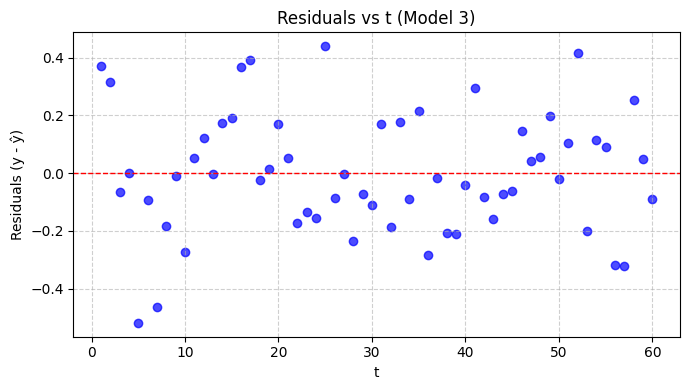

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# --- Estimated parameters (Model 3) ---
# These are from the previous OLS estimation
beta0 = 2.92868348
beta1 = -0.28001731
beta2 = 0.01545709
beta3 = -0.00033854
beta4 = 2.538545e-06

# --- Compute fitted values and residuals ---
# yhat = B0 + B1*t + B2*t^2 + B3 + B4*t^4
yhat = beta0 + beta1 * t + beta2 * (t**2) + beta3 * (t**3) + beta4 * (t**4)
residuals = y_data - yhat

# --- Plot residuals vs t ---
print("Generating residual plot for Model 3...")

plt.figure(figsize=(7, 4))
plt.scatter(t, residuals, color='blue', alpha=0.7)
plt.axhline(0, color='red', linestyle='--', linewidth=1)
plt.xlabel('t')
plt.ylabel('Residuals (y - ŷ)')
plt.title('Residuals vs t (Model 3)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


--- Normality Tests for Model 3 Residuals ---
Shapiro–Wilk test statistic = 0.987349, p-value = 0.790216
  (p > 0.05) Fail to reject H0: Residuals appear to be normally distributed.

D'Agostino–Pearson test statistic = 0.014360, p-value = 0.992846
  (p > 0.05) Fail to reject H0: Residuals appear to be normally distributed.

Anderson–Darling statistic: 0.225404
  Significance levels and critical values:
    15.0%: 0.544 -> Fail to reject H0 (Statistic <= Critical Value)
    10.0%: 0.619 -> Fail to reject H0 (Statistic <= Critical Value)
    5.0%: 0.743 -> Fail to reject H0 (Statistic <= Critical Value)
    2.5%: 0.866 -> Fail to reject H0 (Statistic <= Critical Value)
    1.0%: 1.030 -> Fail to reject H0 (Statistic <= Critical Value)

Generating plots...


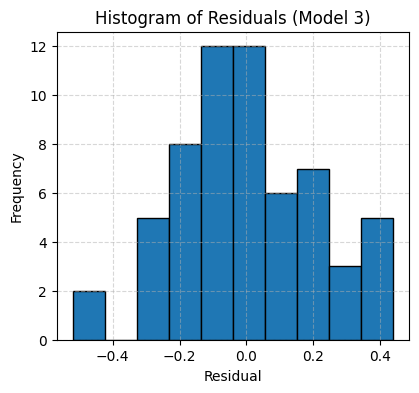

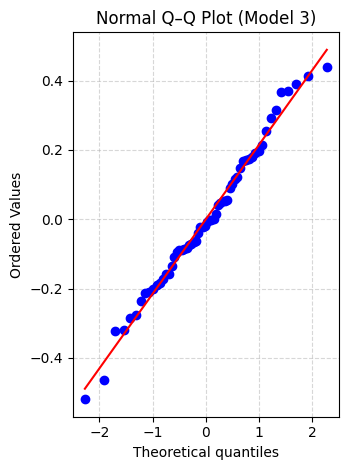

In [ ]:
from scipy.stats import shapiro, normaltest, anderson, probplot
import matplotlib.pyplot as plt
import numpy as np

# --- Estimated parameters (Model 3) ---
# These are from the previous OLS estimation
beta0 = 2.9286834836240576
beta1 = -0.2800173083459407
beta2 = 0.015457088648014095
beta3 = -0.0003385382207501103
beta4 = 2.538544595936967e-06

# --- Compute fitted values and residuals ---
# yhat = B0 + B1*t + B2*t^2 + B3*t^3 + B4*t^4
yhat = beta0 + beta1 * t + beta2 * (t**2) + beta3 * (t**3) + beta4 * (t**4)
residuals = y_data - yhat

print("\n--- Normality Tests for Model 3 Residuals ---")

# --- 1. Shapiro–Wilk test ---
# Null hypothesis (H0): The data is drawn from a normal distribution.
stat_sw, p_sw = shapiro(residuals)
print(f"Shapiro–Wilk test statistic = {stat_sw:.6f}, p-value = {p_sw:.6f}")
if p_sw > 0.05:
    print("  (p > 0.05) Fail to reject H0: Residuals appear to be normally distributed.")
else:
    print("  (p <= 0.05) Reject H0: Residuals do not appear to be normally distributed.")

# --- 2. D'Agostino and Pearson's normality test ---
# Null hypothesis (H0): The data is drawn from a normal distribution.
stat_dp, p_dp = normaltest(residuals)
print(f"\nD'Agostino–Pearson test statistic = {stat_dp:.6f}, p-value = {p_dp:.6f}")
if p_dp > 0.05:
    print("  (p > 0.05) Fail to reject H0: Residuals appear to be normally distributed.")
else:
    print("  (p <= 0.05) Reject H0: Residuals do not appear to be normally distributed.")

# --- 3. Anderson–Darling test ---
# Null hypothesis (H0): The data is drawn from a normal distribution.
result_ad = anderson(residuals)
print(f"\nAnderson–Darling statistic: {result_ad.statistic:.6f}")
print("  Significance levels and critical values:")
for i in range(len(result_ad.critical_values)):
    sl, cv = result_ad.significance_level[i], result_ad.critical_values[i]
    if result_ad.statistic > cv:
        print(f"    {sl}%: {cv:.3f} -> Reject H0 (Statistic > Critical Value)")
    else:
        print(f"    {sl}%: {cv:.3f} -> Fail to reject H0 (Statistic <= Critical Value)")

# --- 4. Plot Histogram and Q–Q Plot ---
print("\nGenerating plots...")
plt.figure(figsize=(10, 4))

# Histogram
plt.subplot(1, 2, 1)
plt.hist(residuals, bins=10, edgecolor='black')
plt.title('Histogram of Residuals (Model 3)')
plt.xlabel('Residual')
plt.ylabel('Frequency')
plt.grid(alpha=0.5, linestyle='--')
plt.show()

# Q–Q Plot
plt.subplot(1, 2, 2)
probplot(residuals, dist="norm", plot=plt)
plt.title('Normal Q–Q Plot (Model 3)')
plt.grid(alpha=0.5, linestyle='--')
plt.tight_layout()
plt.show()